<a href="https://colab.research.google.com/github/jainmithas/BigHacks_R2/blob/main/App_Review_Analysis_Starter_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving reviews.csv to reviews.csv


In [ ]:
import pandas as pd
import re

try:
    df = pd.read_csv('reviews.csv')
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("Error: 'reviews.csv' not found")
    exit()

# data extracttion & pre-processing

# Drop rows where the review content is missing
df.dropna(subset=['content'], inplace=True)

stop_words = set([
    'i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', 'your', 'yours',
    'he', 'him', 'his', 'himself', 'she', 'her', 'hers', 'herself', 'it', 'its', 'itself',
    'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this',
    'that', 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being',
    'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and',
    'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with',
    'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above',
    'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again',
    'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any',
    'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only',
    'own', 'same', 'so', 'than', 'too', 'very', 's', 't', 'can', 'will', 'just', 'don', 'should', 'now',
    'app', 'even', 'get', 'use', 'also', 'game', 'play', 'really', 'still', 'application', 'one',
    'time', 'review', 'phone', 'like'
])  #list of stopwords

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'[^a-z\s]', '', text)  # Remove punctuation and numbers

    words = text.split()
    cleaned_words = [word for word in words if word not in stop_words]  #splitting then filtered using stopwords list

    return " ".join(cleaned_words)

df['cleaned_content'] = df['content'].apply(clean_text)  #clean_text function is applied
print("Text cleaning complete.")

print("\n--- Text stats: ---")

# Word and character counts before cleaning
df['word_count'] = df['content'].apply(lambda x: len(str(x).split()))
df['char_count'] = df['content'].apply(lambda x: len(str(x)))

# Word count after cleaning
df['clean_word_count'] = df['cleaned_content'].apply(lambda x: len(str(x).split()))

# comparison
print("\nSample comparison of text length before and after cleaning:")
print(df[['content', 'word_count', 'cleaned_content', 'clean_word_count']].head())

# avg word count before and after cleaning
print("\nAverage word counts before and after cleaning:")
print(df[['word_count', 'clean_word_count']].mean())

# sentiment analysis
positive_words = [
    'good', 'great', 'love', 'best', 'awesome', 'easy', 'nice', 'excellent',
    'perfect', 'amazing', 'useful', 'helpful', 'happy', 'super', 'fast',
    'enjoy', 'fantastic', 'friendly', 'wonderful', 'beautiful', 'clean', 'simple',
    'recommend', 'loved', 'pleased', 'satisfied', 'thanks', 'cool', 'impressed',
    'smooth', 'convenient', 'quick', 'well', 'efficient', 'reliable', 'organized',
    'productive', 'planner', 'tasks', 'reminder', 'reminders', 'syncs', 'minimalist',
    'please', 'thank', 'appreciate', 'lovely', 'fabulous', 'favorite', 'addictive'
]
negative_words = [
    'bad', 'worst', 'terrible', 'hate', 'bug', 'crash', 'slow', 'useless',
    'error', 'problem', 'confusing', 'difficult', 'sucks', 'fake', 'ads',
    'annoying', 'poor', 'disappointed', 'waste', 'stupid', 'broken', 'glitch',
    'freeze', 'uninstall', 'fix', 'cannot', 'unable', 'doesn\'t work', 'horrible',
    'awful', 'frustrating', 'expensive', 'spam', 'laggy', 'glitchy', 'refund',
    'subscription', 'paid', 'trial', 'lost', 'syncing', 'missing', 'messy',
    'cluttered', 'stopped', 'keeps stopping', 'doesn', 'won', 'can\'t', 'not',
    'nothing', 'never', 'bombarded', 'issues', 'issue', 'force close', 'dislike'
]

def manual_sentiment_analyzer(text):
    words = text.split()
    positive_count = 0
    negative_count = 0

    for word in words:
        if word in positive_words:
            positive_count += 1
        elif word in negative_words:
            negative_count += 1

    score = positive_count - negative_count  #sentiment score is calculated

    # Classify based on the score
    if score > 0:
        label = 'Positive'
    elif score < 0:
        label = 'Negative'
    else:
        label = 'Neutral'

    return pd.Series([score, label])

# apply sentiment analysis to cleaned content
df[['sentiment_score', 'sentiment_label']] = df['cleaned_content'].apply(manual_sentiment_analyzer)
print("Manual sentiment analysis complete.")

print("Successfully transformed the raw data. Here's a sample of the 'BEFORE' and 'AFTER':")

# Show a sample of the original and newly created columns
output_columns = [
    'content',
    'cleaned_content',
    'score',
    'sentiment_score',  # This is our new manual score
    'sentiment_label'
]
print(df[output_columns].head())


print("\nInitial analysis of sentiment distribution vs. user score:")
# Show a crosstab to compare our sentiment label with the user's score
# This is great for showing how well our *manual* method works!
comparison = pd.crosstab(df['score'], df['sentiment_label'])
print(comparison)


Dataset loaded successfully.
Text cleaning complete.

--- Text stats: ---

Sample comparison of text length before and after cleaning:
                                             content  word_count  \
0                      I cannot open the app anymore           6   
1  I have been begging for a refund from this app...          19   
2  Very costly for the premium version (approx In...          36   
3  Used to keep me organized, but all the 2020 UP...          44   
4                                Dan Birthday Oct 28           4   

                                     cleaned_content  clean_word_count  
0                                cannot open anymore                 3  
1               begging refund month nobody replying                 5  
2  costly premium version approx indian rupees pe...                18  
3  used keep organized updates made mess things y...                26  
4                                   dan birthday oct                 3  

Average word coun


Generating Sentiment Distribution Bar Chart...


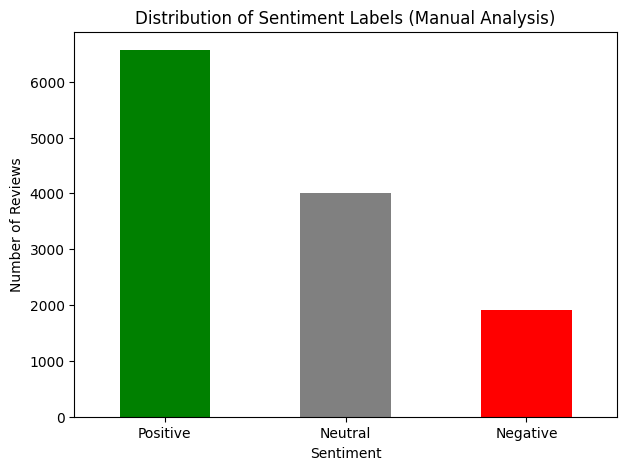

Bar chart complete.

Generating Word Clouds for 1-Star and 5-Star Reviews...


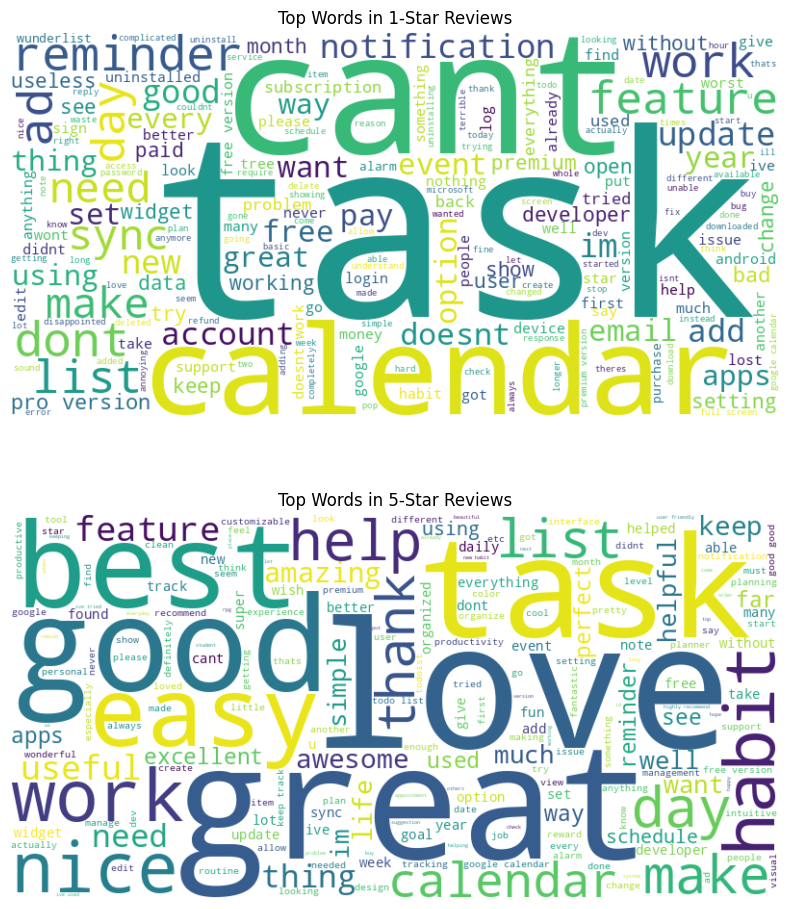

Word clouds complete.


In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
print("\nGenerating Sentiment Distribution Bar Chart...")
try:
    plt.figure(figsize=(7, 5)) # Set the figure size
    df['sentiment_label'].value_counts().plot(kind='bar', color=['green', 'gray', 'red'])
    plt.title("Distribution of Sentiment Labels (Manual Analysis)")
    plt.xlabel("Sentiment")
    plt.ylabel("Number of Reviews")
    plt.xticks(rotation=0) # Keep the labels (Positive, Neutral, Negative) horizontal
    plt.show() # Display the plot
    print("Bar chart complete.")
except Exception as e:
    print(f"Could not plot bar chart. Make sure 'matplotlib' is installed. Error: {e}")

# 2. Advanced Word Clouds (Our "Why" visualization)
print("\nGenerating Word Clouds for 1-Star and 5-Star Reviews...")
try:
    # Isolate 1-star (bad) and 5-star (good) reviews' text
    # We use .dropna() just in case, though our cleaned text should be fine
    bad_reviews_text = " ".join(df[df['score'] == 1]['cleaned_content'].dropna())
    good_reviews_text = " ".join(df[df['score'] == 5]['cleaned_content'].dropna())

    if bad_reviews_text and good_reviews_text: # Check if we have text to plot
        # Create word cloud for BAD reviews
        # --- MODIFIED: Made the figure smaller ---
        plt.figure(figsize=(8, 10)) # Was (10, 14), now smaller

        plt.subplot(2, 1, 1) # 2 rows, 1 column, 1st plot
        wc_bad = WordCloud(width=800, height=400, background_color='white').generate(bad_reviews_text)
        plt.imshow(wc_bad, interpolation='bilinear')
        plt.axis('off')
        plt.title("Top Words in 1-Star Reviews")

        # Create word cloud for GOOD reviews
        plt.subplot(2, 1, 2) # 2 rows, 1 column, 2nd plot
        wc_good = WordCloud(width=800, height=400, background_color='white').generate(good_reviews_text)
        plt.imshow(wc_good, interpolation='bilinear')
        plt.axis('off')
        plt.title("Top Words in 5-Star Reviews")

        plt.tight_layout() # Adjusts plots to prevent overlap
        plt.show() # Display the plots
        print("Word clouds complete.")
    else:
        print("Could not generate word clouds. Not enough text from 1-star or 5-star reviews.")

except Exception as e:
    print(f"Could not generate word clouds. Is 'wordcloud' library installed? Error: {e}")



Aspect extraction:
sample of dataframe w new aspect columns:
                                     cleaned_content  score sentiment_label  \
0                                cannot open anymore      1        Negative   
1               begging refund month nobody replying      1        Negative   
2  costly premium version approx indian rupees pe...      1         Neutral   
3  used keep organized updates made mess things y...      1        Positive   
4                                   dan birthday oct      1         Neutral   

   Bugs/Performance  Features/Functionality  UI/UX  Monetization/Ads  \
0             False                   False  False             False   
1             False                   False  False              True   
2             False                   False  False             False   
3             False                   False  False             False   
4             False                   False  False             False   

   Account/Data  Churn_Signal 

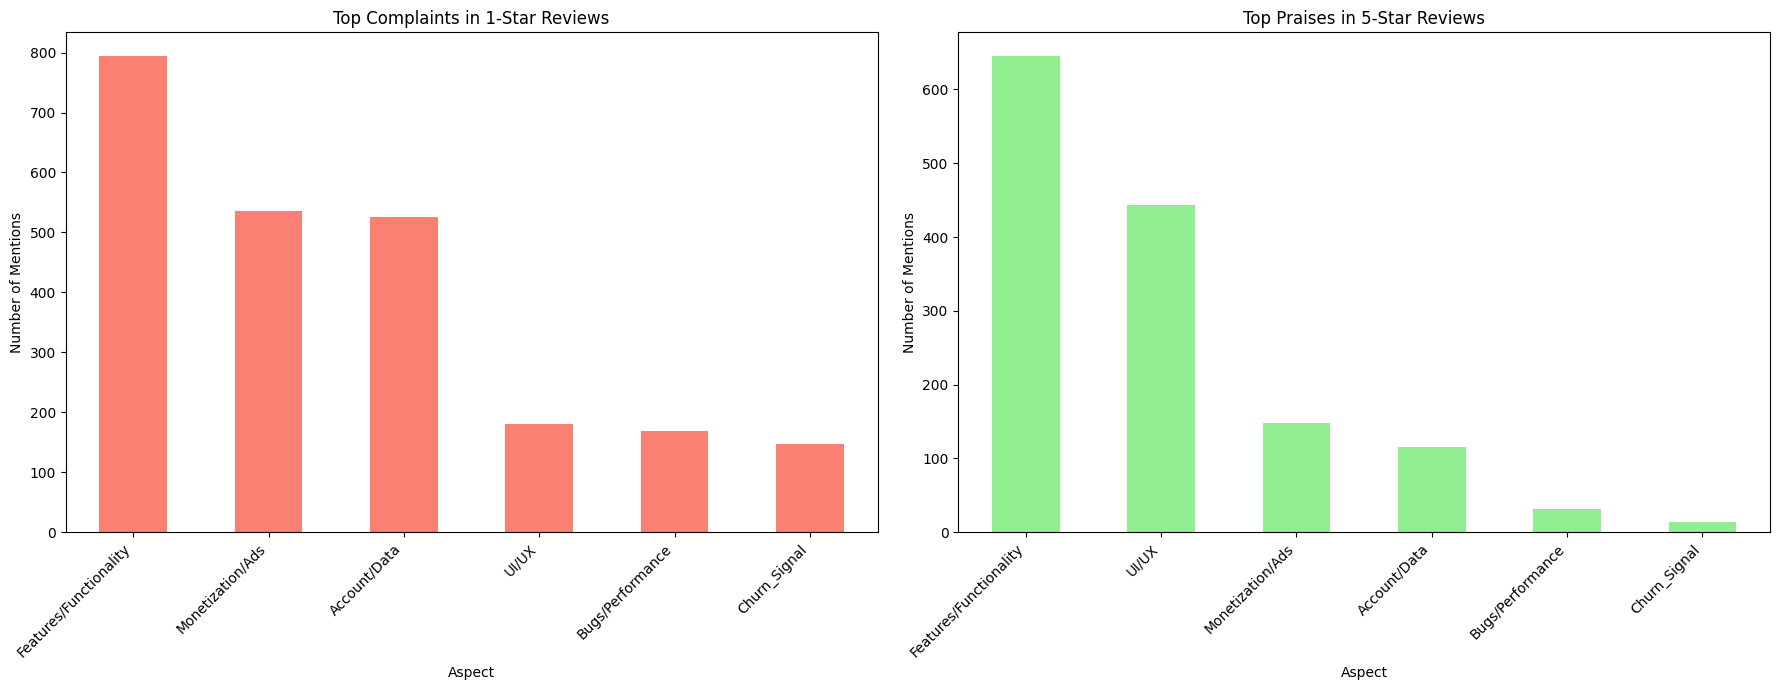

'Top Complaints & Praises' charts complete.

What do 'helpful' reviews talk about?
Found 769 'helpful' reviews (thumbsUpCount > 10) to analyze.


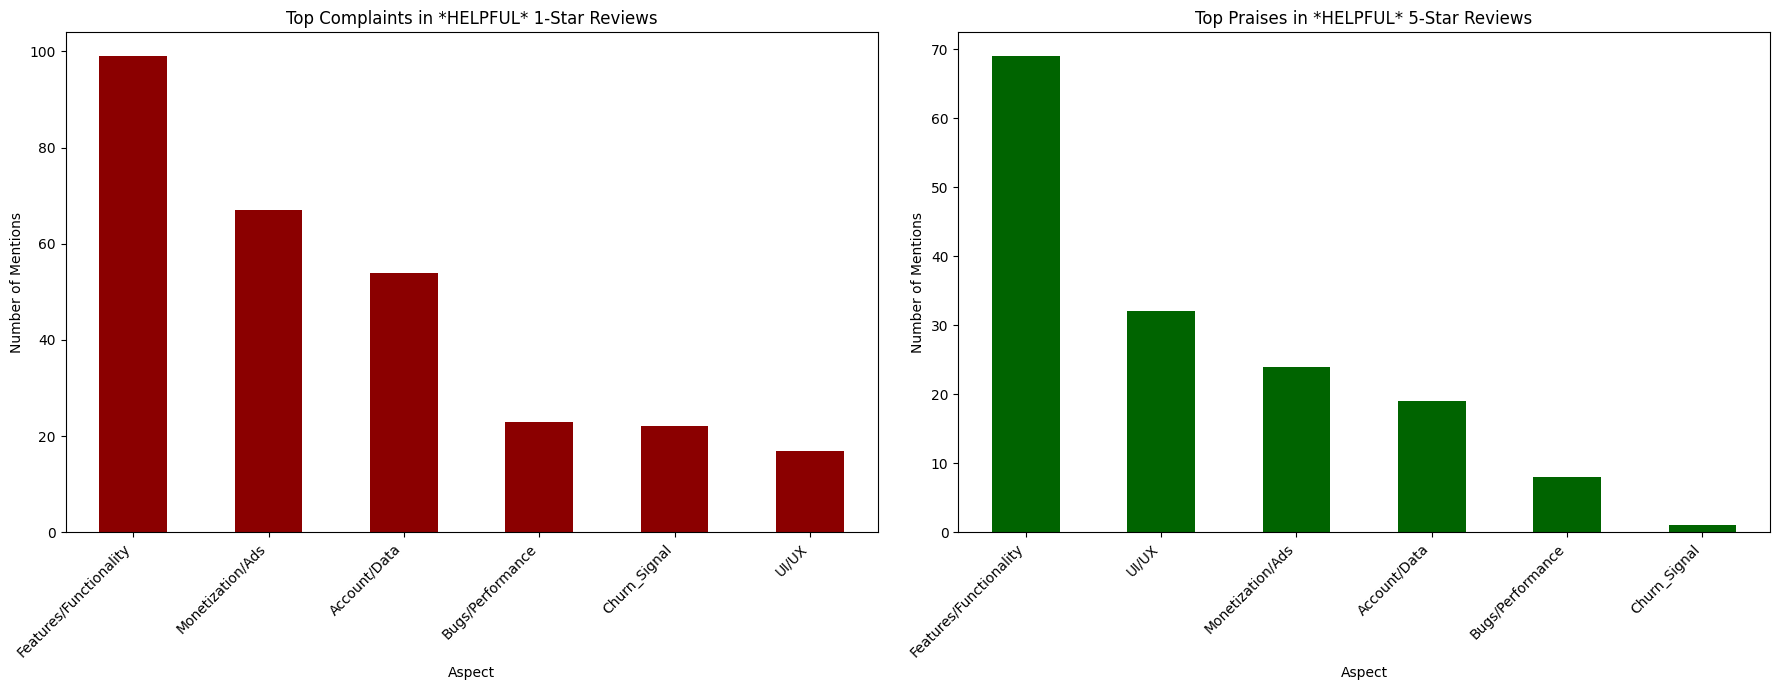

'Helpful Reviews' analysis complete.
Successfully saved transformed dataset as 'analyzed_reviews.csv'.
New dataset preview:
       appId                   at  score  thumbsUpCount  \
0  com.anydo  2020-10-27 21:24:41      1              0   
1  com.anydo  2020-10-27 14:03:28      1              0   
2  com.anydo  2020-10-27 08:18:40      1              0   
3  com.anydo  2020-10-26 13:28:07      1              0   
4  com.anydo  2020-10-26 06:10:50      1              0   

                                     cleaned_content  sentiment_score  \
0                                cannot open anymore               -1   
1               begging refund month nobody replying               -1   
2  costly premium version approx indian rupees pe...                0   
3  used keep organized updates made mess things y...                2   
4                                   dan birthday oct                0   

  sentiment_label  Bugs/Performance  Features/Functionality  UI/UX  \
0        Neg

In [ ]:
# aspect extraction
print("\nAspect extraction:")

aspect_keywords = {
    'Bugs/Performance': ['crash', 'bug', 'slow', 'lag', 'glitch', 'error', 'freeze', 'stuck', 'doesn\'t work', 'broken', 'stopped', 'won\'t open', 'deleting', 'saving'],
    'Features/Functionality': ['feature', 'option', 'add', 'suggestion', 'update', 'needs', 'wish', 'request', 'implement', 'missing', 'tasks', 'goals', 'reminders', 'planner', 'lists', 'calendar', 'widget'],
    'UI/UX': ['ui', 'interface', 'design', 'layout', 'easy', 'simple', 'confusing', 'hard to use', 'navigation', 'look', 'cluttered', 'messy', 'minimalist', 'clean'],
    'Monetization/Ads': ['ads', 'payment', 'price', 'subscription', 'purchase', 'expensive', 'free', 'trial', 'cost', 'buy', 'paid', 'refund'],
    'Account/Data': ['account', 'login', 'sync', 'syncing', 'data', 'profile', 'save', 'lost', 'sign in', 'password', 'google', 'device', 'devices'],
    'Churn_Signal': ['uninstall', 'switching', 'leaving', 'cancel', 'refund', 'stopped using', 'quit', 'delete', 'goodbye', 'bye']
}

def extract_aspects(text):
    mentioned_aspects = {}
    words = text.split()

    for aspect_name, keywords in aspect_keywords.items():
        found = False
        for word in words:
            if word in keywords:
                found = True
                break # Move to the next aspect
        mentioned_aspects[aspect_name] = found

    return pd.Series(mentioned_aspects)

# Checking for and removing old aspect columns to prevent duplicates
for aspect in aspect_keywords.keys():
    if aspect in df.columns:
        df.drop(columns=[aspect], inplace=True)

aspect_df = df['cleaned_content'].apply(extract_aspects)
df = pd.concat([df, aspect_df], axis=1)

# for output
print("sample of dataframe w new aspect columns:")
new_output_columns = [
    'cleaned_content',
    'score',
    'sentiment_label',
    'Bugs/Performance',
    'Features/Functionality',
    'UI/UX',
    'Monetization/Ads',
    'Account/Data',
    'Churn_Signal'
]
print(df[new_output_columns].head())

print("\nGenerating 'Top Complaints & Praises' visualizations...")
try:
    # Filter for bad reviews (1-star)
    bad_reviews = df[df['score'] == 1]
    aspect_complaints = bad_reviews[aspect_keywords.keys()].sum().sort_values(ascending=False) # Sort

    # Filter for good reviews (5-star)
    good_reviews = df[df['score'] == 5]
    aspect_praises = good_reviews[aspect_keywords.keys()].sum().sort_values(ascending=False) # Sort

    plt.figure(figsize=(18, 7)) # to plot the 2 graphs

    # Top Complaints graph
    plt.subplot(1, 2, 1)
    aspect_complaints.plot(kind='bar', color='salmon')
    plt.title("Top Complaints in 1-Star Reviews")
    plt.ylabel("Number of Mentions")
    plt.xlabel("Aspect")
    plt.xticks(rotation=45, ha='right')

    # Top Praises graph
    plt.subplot(1, 2, 2)
    aspect_praises.plot(kind='bar', color='lightgreen')
    plt.title("Top Praises in 5-Star Reviews")
    plt.ylabel("Number of Mentions")
    plt.xlabel("Aspect")
    plt.xticks(rotation=45, ha='right')

    plt.tight_layout() # to adjust plots
    plt.show()
    print("'Top Complaints & Praises' charts complete.")

except Exception as e:
    print(f"Could not plot 'Top Complaints & Praises' charts. Error: {e}")

print("\nWhat do 'helpful' reviews talk about?")
try:
    helpful_reviews = df[df['thumbsUpCount'] > 10].copy()  #helpful reviewws are defined as ones > 10
    print(f"Found {len(helpful_reviews)} 'helpful' reviews (thumbsUpCount > 10) to analyze.")

    if len(helpful_reviews) > 0:
        # Separate helpful reviews into bad (1-star) and good (5-star)
        helpful_bad = helpful_reviews[helpful_reviews['score'] == 1]
        helpful_good = helpful_reviews[helpful_reviews['score'] == 5]

        helpful_complaints = helpful_bad[aspect_keywords.keys()].sum().sort_values(ascending=False)
        helpful_praises = helpful_good[aspect_keywords.keys()].sum().sort_values(ascending=False)

        # plotting
        plt.figure(figsize=(18, 7))

        # Helpful Complaints graph
        plt.subplot(1, 2, 1)
        helpful_complaints.plot(kind='bar', color='darkred')
        plt.title("Top Complaints in *HELPFUL* 1-Star Reviews")
        plt.ylabel("Number of Mentions")
        plt.xlabel("Aspect")
        plt.xticks(rotation=45, ha='right')

        # Helpful Praises graph
        plt.subplot(1, 2, 2)
        helpful_praises.plot(kind='bar', color='darkgreen')
        plt.title("Top Praises in *HELPFUL* 5-Star Reviews")
        plt.ylabel("Number of Mentions")
        plt.xlabel("Aspect")
        plt.xticks(rotation=45, ha='right')

        plt.tight_layout()
        plt.show()
        print("'Helpful Reviews' analysis complete.")
    else:
        print("No 'helpful' reviews found with > 10 thumbs ups. Skipping this analysis.")

except Exception as e:
    print(f"Could not plot 'Helpful Reviews' analysis. Error: {e}")


# exporting final csv

final_columns = [
    'appId',
    'at',
    'score',
    'thumbsUpCount',
    'cleaned_content',
    'sentiment_score',
    'sentiment_label',
    'Bugs/Performance',
    'Features/Functionality',
    'UI/UX',
    'Monetization/Ads',
    'Account/Data',
    'Churn_Signal'
]  #keeping columns we need for visualising

final_df = df[final_columns].copy()

try:
    output_filename = 'analyzed_reviews.csv'
    final_df.to_csv(output_filename, index=False, encoding='utf-8')
    print(f"Successfully saved transformed dataset as '{output_filename}'.")
except Exception as e:
    print(f"Error saving file: {e}")

print("New dataset preview:")
# Set display options to show all columns
pd.set_option('display.max_columns', None)
print(final_df.head())
